# Module 01: Battery Ageing by Charge Level, Charging Speed and Temperature

## Why this notebook

SparkEV's What-If Simulator lets a driver compare charging options, for example charging to
80 % or to 100 %, or using a faster charger. To show the battery-health cost of each option it
needs a model that links **how a battery is charged** to **how fast it loses capacity**.

The models built so far cannot give this:

- **Module 3** forecasts SOH from charging-cycle measurements, but almost every charge in its
  data ends at 95-100 % (median 99 %; none of the 109 batteries typically stops below 90 %).
  A model cannot learn the effect of stopping at 80 % from data where nobody does.
- **The capacity-fade model of notebook 02** (fitted on NASA and CALCE data) has a C-rate and a
  charge-throughput term, but no state-of-charge term, because neither dataset varies the charge
  window.

This notebook uses an open laboratory ageing dataset designed to measure exactly these effects.

## Data

Luh, M. & Blank, T. (2024). *Comprehensive battery aging dataset: capacity and impedance fade
measurements of a lithium-ion NMC/C-SiO cell.* Scientific Data, doi:10.1038/s41597-024-03831-x.
Dataset version 2 (result data), Karlsruhe Institute of Technology, doi:10.35097/1969,
licence CC BY 4.0.

228 commercial 18650 cells (NMC cathode, graphite-silicon anode, 3 Ah) aged for up to 600 days,
3 cells per test condition:

| Test | Conditions |
|---|---|
| Storage (calendar ageing) | stored at 10, 50, 90 or 100 % SoC |
| Cycling | charge window 0-100 %, 10-100 % or 10-90 %; charging at 1/3, 1 or 5/3 C; discharging at 1/3 or 1 C |
| Temperature (both) | 0, 10, 25, 40 °C |

The capacity of every cell was measured in regular check-ups under standard conditions. This
notebook uses the end-of-charge result files (`cell_eocv2_*.csv`), placed in `data/raw/cell_eocv2/`.

## Approach

1. For every cell, measure how fast its capacity falls: per equivalent full cycle for the
   cycling cells, and per square root of time for the storage cells (calendar ageing typically
   follows √t).
2. Compare the conditions directly (3 cells each).
3. Fit a model for the cycling wear that the What-If Simulator can use for any charge level and
   charging speed, and validate it on test conditions it has not seen.

## 1. Setup

In [1]:
import glob
import json
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

DATA_DIR = Path(os.environ.get("SPARKEV_KIT_DATA", Path("..") / ".." / "data" / "raw" / "cell_eocv2"))
NOMINAL_AH = 3.0            # nominal capacity of the cell
EARLY_LOSS_LIMIT = 20.0     # use the first 20 points of capacity loss (early life)
MIN_EFC = 20                # cycling cells need at least 20 full cycles of early-life data

files = sorted(glob.glob(str(DATA_DIR / "cell_eocv2_P*.csv")))
print("Result files:", len(files))

Result files: 240


## 2. Capacity fade of every cell

Rows with `cyc_condition == 2` are check-ups; their discharge rows hold the measured capacity
(`soh_cap`, % of nominal). `total_q_chg_sum_Ah` is the total charge put into the cell, so
`charge / 3 Ah` is the number of equivalent full cycles (EFC).

- **Cycling cells:** capacity loss is close to linear in EFC early in life, so the wear rate is
  the slope of loss against EFC (points of capacity per cycle).
- **Storage cells:** the loss is fitted as `k · √days`.

Only the first 20 points of capacity loss are used (roughly 97 % down to 77 %). This is the range
that matters for a vehicle, and late-life estimates in the files become unreliable. The 12
`P000` files are empty placeholders and are skipped; the 36 driving-profile cells (age type 3)
are not used here. Cycling cells that failed before completing 20 full cycles (mostly fast
charging at 0 °C, where lithium plating destroys the cell almost at once) cannot give a wear
rate and are excluded; the notebook lists them.

In [2]:
rows, too_short = [], []
for path in files:
    pid = int(re.search(r"_P(\d+)_", path).group(1))
    if pid == 0:
        continue
    d = pd.read_csv(path, sep=";")
    age_type = int(d["age_type"].mode()[0])
    if age_type not in (1, 2):
        continue
    cu = d[(d["cyc_condition"] == 2) & (d["cyc_charged"] == 0) & d["soh_cap"].notna()].copy()
    if len(cu) < 3:
        continue
    op = d[d["cyc_condition"] == 1]
    cu["days"] = (cu["timestamp_s"] - cu["timestamp_s"].iloc[0]) / 86400
    cu["efc"] = (cu["total_q_chg_sum_Ah"] - cu["total_q_chg_sum_Ah"].iloc[0]) / NOMINAL_AH
    cu["loss"] = cu["soh_cap"].iloc[0] - cu["soh_cap"]
    early = cu[cu["loss"] <= EARLY_LOSS_LIMIT]
    if age_type == 2 and early["efc"].max() < MIN_EFC:
        too_short.append(os.path.basename(path)[11:20])   # failed before it could be measured
        continue
    x = np.sqrt(early["days"].values) if age_type == 1 else early["efc"].values
    rate = float(np.linalg.lstsq(x[:, None], early["loss"].values, rcond=None)[0][0])
    rows.append(dict(
        param_id=pid, cell=os.path.basename(path)[11:20], age_type=age_type,
        temp_c=int(d["age_temp"].mode()[0]), storage_soc=float(d["age_soc"].mode()[0]),
        chg_c=float(d["age_chg_rate"].mode()[0]), dis_c=float(d["age_dischg_rate"].mode()[0]),
        v_max=float(op["v_max_target_V"].mode()[0]) if len(op) else np.nan,
        v_min=float(op["v_min_target_V"].mode()[0]) if len(op) else np.nan,
        checkups=len(cu), days=float(cu["days"].max()), efc=float(cu["efc"].max()),
        soh_start=float(cu["soh_cap"].iloc[0]), rate=rate))
cells_df = pd.DataFrame(rows)


def window(r):
    if r.age_type == 1:
        return "storage"
    if r.v_min < 3.0:
        return "0-100"
    return "10-90" if r.v_max < 4.15 else "10-100"


cells_df["window"] = cells_df.apply(window, axis=1)
print(cells_df.groupby(["age_type", "window"]).size().rename("cells"))
print(f"\nCycling cells excluded (fewer than {MIN_EFC} full cycles before failing): {len(too_short)}", too_short)

age_type  window 
1         storage    48
2         0-100      33
          10-100     45
          10-90      48
Name: cells, dtype: int64

Cycling cells excluded (fewer than 20 full cycles before failing): 15 ['P017_1_S0', 'P017_2_S0', 'P017_3_S0', 'P019_2_S0', 'P019_3_S0', 'P020_1_S0', 'P020_2_S0', 'P020_3_S0', 'P024_2_S0', 'P029_1_S0', 'P029_2_S0', 'P029_3_S0', 'P032_1_S0', 'P032_2_S0', 'P032_3_S0']


## 3. Storage: ageing while parked at a charge level

In [3]:
storage = cells_df[cells_df["age_type"] == 1]
storage_table = storage.pivot_table(index="storage_soc", columns="temp_c", values="rate", aggfunc="mean")
print("Capacity loss coefficient k (points per sqrt(day)), mean of 3 cells")
print(storage_table.round(3).to_string())
print("\nRelative to storage at 50 % SoC:")
(storage_table / storage_table.loc[50.0]).round(2)

Capacity loss coefficient k (points per sqrt(day)), mean of 3 cells
temp_c          0      10     25     40
storage_soc                            
10.0         0.560  0.544  0.585  0.710
50.0         0.639  0.676  0.703  1.019
90.0         0.830  0.820  0.881  1.242
100.0        0.807  0.844  0.868  1.028

Relative to storage at 50 % SoC:


temp_c,0,10,25,40
storage_soc,,,,
10.0,0.88,0.81,0.83,0.70
50.0,1.00,1.00,1.00,1.00
90.0,1.30,1.21,1.25,1.22
100.0,1.26,1.25,1.23,1.01


## 4. Cycling: wear per full cycle by charge window and charging speed

In [4]:
cycling = cells_df[cells_df["age_type"] == 2].copy()
cycling["loss_per_100_efc"] = cycling["rate"] * 100
for temp in (25, 10, 40, 0):
    t = cycling[cycling["temp_c"] == temp].pivot_table(
        index="window", columns=["chg_c", "dis_c"], values="loss_per_100_efc", aggfunc="mean")
    print(f"\n{temp} °C: capacity loss (points) per 100 equivalent full cycles, mean of 3 cells")
    print(t.round(1).to_string())

spread = cycling.groupby("param_id")["rate"].agg(lambda s: s.std() / s.mean())
print(f"\nAgreement of the 3 cells per condition: median coefficient of variation {spread.median():.1%}")


25 °C: capacity loss (points) per 100 equivalent full cycles, mean of 3 cells
chg_c   0.33        1.00  1.67
dis_c   0.33  1.00  1.00  1.00
window                        
0-100   22.0  35.8  33.5  35.5
10-100   7.6   6.5   7.3   8.0
10-90    4.6   4.2   4.0   5.3

10 °C: capacity loss (points) per 100 equivalent full cycles, mean of 3 cells
chg_c  0.33        1.00  1.67
dis_c  0.33  1.00  1.00  1.00
window                       
0-100   NaN  41.0  42.6   NaN
10-100  9.4  11.7  10.9  32.5
10-90   5.6   5.7   6.8  10.9

40 °C: capacity loss (points) per 100 equivalent full cycles, mean of 3 cells
chg_c   0.33        1.00  1.67
dis_c   0.33  1.00  1.00  1.00
window                        
0-100   22.6  36.0  31.2  30.5
10-100   8.9   7.4   6.6   6.8
10-90    5.9   5.0   3.9   4.5

0 °C: capacity loss (points) per 100 equivalent full cycles, mean of 3 cells
chg_c   0.33        1.00  1.67
dis_c   0.33  1.00  1.00  1.00
window                        
0-100    NaN  46.4  48.0   NaN
10-100  1

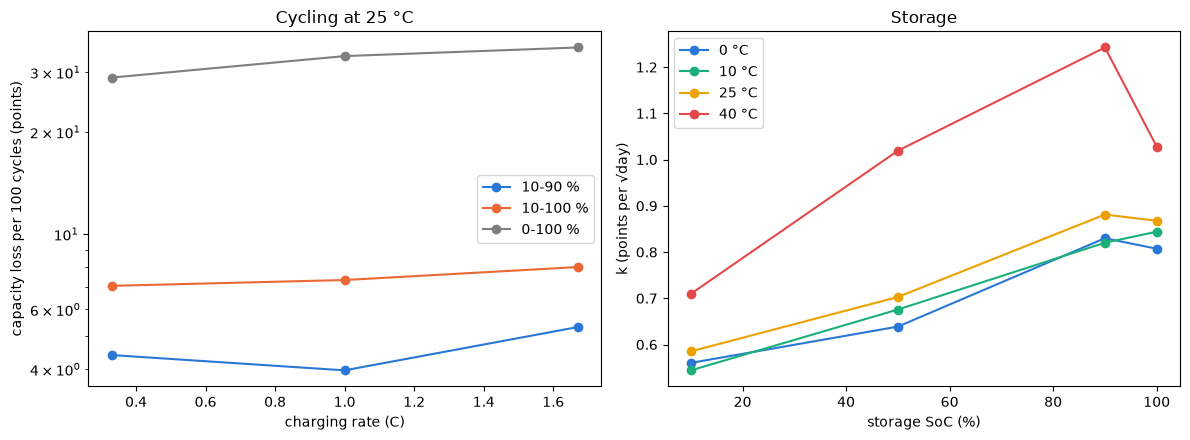

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
c25 = cycling[cycling["temp_c"] == 25]
for w, color in [("10-90", "#2a78d6"), ("10-100", "#eb6834"), ("0-100", "#7f7f7f")]:
    s = c25[c25["window"] == w].groupby("chg_c")["loss_per_100_efc"].mean()
    axes[0].plot(s.index, s.values, "o-", color=color, label=f"{w} %")
axes[0].set_xlabel("charging rate (C)"); axes[0].set_ylabel("capacity loss per 100 cycles (points)")
axes[0].set_title("Cycling at 25 °C"); axes[0].legend(); axes[0].set_yscale("log")
for temp, color in [(0, "#2a78d6"), (10, "#1baf7a"), (25, "#eda100"), (40, "#e34948")]:
    s = storage_table[temp]
    axes[1].plot(s.index, s.values, "o-", color=color, label=f"{temp} °C")
axes[1].set_xlabel("storage SoC (%)"); axes[1].set_ylabel("k (points per √day)")
axes[1].set_title("Storage"); axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Cycling wear model

The What-If Simulator charges a car **from its current level up to a chosen level**. The cycling
tests that match this are the two windows that start at 10 %: **10-90 % and 10-100 %**. The
0-100 % window additionally empties the cell completely, which an EV battery management system
does not allow, so it is not used for the model.

Model (log-linear, fitted on all cells of the 10-90 % and 10-100 % windows at all
temperatures):

`log(wear per cycle) = b0 + b1·[charged to 100 %] + b2·log(charge rate) + b3·log(discharge rate)
                       + temperature effect + b4·log(charge rate)·[temperature ≤ 10 °C]`

The last term captures that fast charging in the cold is much more harmful (lithium plating).

**Validation:** leave one test condition out. All 3 cells of a condition are removed, the model
is fitted on the others and predicts the held-out condition.

In [6]:
model_cells = cycling[cycling["window"].isin(["10-90", "10-100"])].copy()


def design(df):
    X = pd.DataFrame({
        "to_100": (df["window"] == "10-100").astype(float),
        "log_chg": np.log(df["chg_c"] / (1 / 3)),
        "log_dis": np.log(df["dis_c"] / (1 / 3)),
        "t0": (df["temp_c"] == 0).astype(float),
        "t10": (df["temp_c"] == 10).astype(float),
        "t40": (df["temp_c"] == 40).astype(float),
    }, index=df.index)
    X["log_chg_cold"] = X["log_chg"] * (df["temp_c"] <= 10)
    return X


y = np.log(model_cells["rate"])
X = design(model_cells)
fit = LinearRegression().fit(X, y)
coef = pd.Series(fit.coef_, index=X.columns)

# leave one test condition (all 3 cells) out
pred = pd.Series(index=model_cells.index, dtype=float)
for pid in model_cells["param_id"].unique():
    held = model_cells["param_id"] == pid
    m = LinearRegression().fit(X[~held], y[~held])
    pred[held] = m.predict(X[held])
cond = pd.DataFrame({"measured": np.exp(y), "predicted": np.exp(pred),
                     "param_id": model_cells["param_id"]}).groupby("param_id").mean()
print(f"Cells used: {len(model_cells)} | test conditions: {len(cond)}")
print(f"Leave-one-condition-out R² (log wear per cycle, per condition): "
      f"{r2_score(np.log(cond['measured']), np.log(cond['predicted'])):.3f}")
print(f"Median error per held-out condition: "
      f"{(abs(cond['predicted'] / cond['measured'] - 1)).median():.1%}")
print(f"\nCharging to 100 % instead of 90 %: wear per cycle x {np.exp(coef['to_100']):.2f}")
print(f"Charging rate x2 at 25 °C: wear per cycle x {2 ** coef['log_chg']:.2f}")
print(f"Charging rate x2 at 10 °C or colder: wear per cycle x {2 ** (coef['log_chg'] + coef['log_chg_cold']):.2f}")
coef.round(4)

Cells used: 93 | test conditions: 31
Leave-one-condition-out R² (log wear per cycle, per condition): 0.785
Median error per held-out condition: 14.6%

Charging to 100 % instead of 90 %: wear per cycle x 1.80
Charging rate x2 at 25 °C: wear per cycle x 0.98
Charging rate x2 at 10 °C or colder: wear per cycle x 1.42


to_100          0.5857
log_chg        -0.0273
log_dis        -0.0358
t0              0.4829
t10             0.1874
t40             0.0346
log_chg_cold    0.5323
dtype: float64

## 6. Wear of one charging session

For the What-If Simulator, the wear of one charge from the current level to a target level is

`wear = (energy charged / battery capacity) · wear per cycle(target, charging rate)`

- **Target level:** the data measures charging to 90 % and to 100 %. Between them the wear per
  cycle is interpolated on a log scale. Below 90 % no lower value is assumed: the model gives the
  90 % value, so it never claims a benefit the data does not show.
- **Charging rate:** EV home and destination charging is often slower than the slowest tested
  rate (1/3 C). Rates below 1/3 C are evaluated at 1/3 C, again claiming no extra benefit.
- **Temperature:** 25 °C unless given.

Ageing while the car stays parked at the reached level is reported separately, from the storage
results (interpolated between the tested levels).

In [7]:
def cycle_wear_rate(target_soc, c_rate, temp_c=25.0, dis_c=1 / 3):
    # capacity points lost per equivalent full cycle
    def rate(to_100):
        df = pd.DataFrame({"window": ["10-100" if to_100 else "10-90"], "chg_c": [max(c_rate, 1 / 3)],
                           "dis_c": [dis_c], "temp_c": [temp_c]})
        return float(np.exp(fit.predict(design(df))[0]))
    frac = float(np.clip((target_soc - 90.0) / 10.0, 0.0, 1.0))
    return float(np.exp((1 - frac) * np.log(rate(False)) + frac * np.log(rate(True))))


def session_wear(energy_kwh, battery_kwh, target_soc, c_rate, temp_c=25.0):
    return energy_kwh / battery_kwh * cycle_wear_rate(target_soc, c_rate, temp_c)


def storage_factor(soc, temp_c=25):
    # ageing rate while parked at this SoC, relative to 50 % SoC
    s = storage_table[temp_c]
    return float(np.interp(soc, s.index.values, s.values) / s.loc[50.0])


battery_kwh = 24.8          # demo driver 17 (Module 2)
examples = [("84 % at 7 kW (0.28 C)", 8.2, 84.4, 7 / battery_kwh),
            ("100 % at 7 kW", 12.6, 100, 7 / battery_kwh),
            ("84 % at 22 kW (car limit 11 kW, 0.44 C)", 8.2, 84.4, 11 / battery_kwh)]
base = session_wear(8.2, battery_kwh, 84.4, 7 / battery_kwh)
pd.DataFrame([dict(option=n, capacity_loss_points=session_wear(e, battery_kwh, t, c),
                   relative_to_first=session_wear(e, battery_kwh, t, c) / base,
                   parked_ageing_vs_50pct=storage_factor(t))
              for n, e, t, c in examples]).round(4)

,option,capacity_loss_points,relative_to_first,parked_ageing_vs_50pct
0,84 % at 7 kW (0.28 C),0.0148,1.0000,1.2182
1,100 % at 7 kW,0.0408,2.7600,1.2345
2,"84 % at 22 kW (car limit 11 kW, 0.44 C)",0.0147,0.9922,1.2182


## 7. Export for the backend

In [8]:
export = dict(
    description="Battery ageing model from the KIT NMC/C-SiO ageing dataset "
                "(notebooks/module1_battery_stress/04_charge_level_ageing_model.ipynb)",
    source="Luh & Blank (2024), Scientific Data, doi:10.1038/s41597-024-03831-x; data doi:10.35097/1969, CC BY 4.0",
    cycle_model=dict(intercept=float(fit.intercept_), coef={k: float(v) for k, v in coef.items()},
                     min_charge_rate_c=1 / 3, tested_targets=[90, 100], reference_discharge_rate_c=1 / 3),
    storage_k=dict(soc=[float(s) for s in storage_table.index],
                   by_temp={str(t): [float(v) for v in storage_table[t]] for t in storage_table.columns}),
    validation=dict(loco_r2_log=float(r2_score(np.log(cond["measured"]), np.log(cond["predicted"]))),
                    loco_median_abs_error=float((abs(cond["predicted"] / cond["measured"] - 1)).median()),
                    cells=int(len(model_cells)), conditions=int(len(cond))),
)
out_path = Path("..") / ".." / "models" / "battery_ageing_kit.json"
json.dump(export, open(out_path, "w"), indent=1)
print("written:", out_path)

written: ../../models/battery_ageing_kit.json


## 8. Findings

The numbers below are from the run shown in this notebook.

1. **Charge level matters most.** Cycling to 100 % instead of 90 % (both from 10 %) increases the
   wear per cycle by a factor of **1.8** (model; 1.5 to 1.8 in the raw 25 °C tables). Emptying the
   battery completely (0-100 %) is far worse still, about 5 to 8 times the 10-90 % wear at 25 °C.
2. **Parking at a high level ages the battery faster.** Stored at 90-100 %, the cells lost
   capacity about 1.2 to 1.3 times faster than at 50 % (25 °C); at 10 % they aged the slowest.
3. **Charging speed matters in the cold, hardly at room temperature.** At 25 °C, doubling the
   charging rate changes the wear per cycle by a factor of 0.98 (no measurable effect between
   1/3 C and 5/3 C). At 10 °C or colder it multiplies the wear by 1.42 per doubling, and at 0 °C
   the fastest charging destroyed several cells within 20 cycles.
4. **The model generalises to unseen conditions.** Leaving out each test condition in turn
   (3 cells each), the model predicts its wear with R² 0.79 on a log scale and a median error of
   15 %. The 3 cells of a condition agree closely (median coefficient of variation 3.6 %).
5. **For the What-If Simulator**, one charge to 100 % instead of the recommended 84 % (driver 17,
   7 kW charger) costs **2.8 times** the battery wear: more energy is charged, and at a higher
   wear rate per cycle.

### Limitations

- One cell type (NMC cathode, graphite-silicon anode, 3 Ah 18650), tested in the laboratory.
  EV battery packs with other chemistries (for example LFP) age differently in size; the
  direction of the effects (high charge level and cold fast charging age the battery more) is
  well established in the literature.
- Charge windows that end below 90 % were not tested, so the model assumes no extra benefit for
  targets below 90 %; real batteries are likely to age even more slowly there. In the same way,
  charging rates below 1/3 C are evaluated at 1/3 C.
- Laboratory cycling compresses months of use into continuous cycling; real driving includes
  rest periods, where the storage results apply.
- Only the first 20 points of capacity loss are used, the range relevant for vehicles.